<a href="https://colab.research.google.com/github/DAlarconAlarcon/Mineria-de-datos/blob/main/Lab01_EDA_Alarcon_Diego.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
print("Librerias cargadas correctamente")

Librerias cargadas correctamente


In [ ]:
from google.colab import files
archivos_subidos = files.upload()
nombre_csv = next(iter(archivos_subidos))
print("Archivo seleccionado:", nombre_csv)

Saving netflix_titles.csv to netflix_titles (1).csv
Archivo seleccionado: netflix_titles (1).csv


In [ ]:
df = pd.read_csv(nombre_csv)
print("Dataset cargado correctamente")
df.head()

Dataset cargado correctamente


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
filas, columnas = df.shape
print("Cantidad de filas:", filas)
print("Cantidad de columnas:", columnas)
display(df.head())
display(df.tail())
display(df.sample(n=min(5, len(df)), random_state=42))
print("Columnas disponibles:")
for numero, columna in enumerate(df.columns, start=1):
    print(numero, "-", columna)
df.info()

resumen_columnas = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "datos_presentes": df.notna().sum(),
    "datos_nulos": df.isna().sum(),
    "valores_unicos": df.nunique(dropna=True)
})
resumen_columnas
columnas_numericas = df.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Columnas numericas:", columnas_numericas)
print("Columnas categoricas:", columnas_categoricas)

Cantidad de filas: 8807
Cantidad de columnas: 12


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
4970,s4971,Movie,"Game Over, Man!",Kyle Newacheck,"Adam DeVine, Anders Holm, Blake Anderson, Utka...",United States,"March 23, 2018",2018,TV-MA,102 min,"Action & Adventure, Comedies",Three buddies with big dreams go from underach...
3362,s3363,Movie,Arsenio Hall: Smart & Classy,Brian Volk-Weiss,Arsenio Hall,United States,"October 29, 2019",2019,TV-MA,63 min,Stand-Up Comedy,"In his first stand-up special, Arsenio Hall di..."
5494,s5495,TV Show,Kazoops!,NaN,"Reece Pockney, Scott Langley, Alex Babic, Gemm...",Australia,"May 5, 2017",2017,TV-Y,3 Seasons,Kids' TV,Music meets imagination in this inventive anim...
1688,s1689,TV Show,We Are the Champions,NaN,NaN,United States,"November 17, 2020",2020,TV-MA,1 Season,"Docuseries, Reality TV","Explore an array of unique competitions, from ..."
1349,s1350,TV Show,"Pablo Escobar, el patrón del mal",NaN,"Andrés Parra, Angie Cepeda, Cecilia Navia, Vic...",Colombia,"February 3, 2021",2012,TV-MA,1 Season,"Crime TV Shows, International TV Shows, Spanis...",From his days as a petty thief to becoming hea...


Columnas disponibles:
1 - show_id
2 - type
3 - title
4 - director
5 - cast
6 - country
7 - date_added
8 - release_year
9 - rating
10 - duration
11 - listed_in
12 - description
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
Columnas numericas: ['release_year']
Columnas categoricas: ['show_id', 'type

In [ ]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().mean() * 100).round(2)
})
resumen_nulos = resumen_nulos.sort_values(by="porcentaje_nulos", ascending=False)
resumen_nulos
columnas_con_nulos = resumen_nulos[resumen_nulos["cantidad_nulos"] > 0]
columnas_con_nulos
cantidad_duplicados = df.duplicated().sum()
porcentaje_duplicados = cantidad_duplicados / len(df) * 100

print("Filas duplicadas:", cantidad_duplicados)
print("Porcentaje duplicado:", round(porcentaje_duplicados, 2), "%")
df[df.duplicated(keep=False)].head(10)
valores_diferentes = df.nunique(dropna=False).sort_values()
valores_diferentes


Filas duplicadas: 0
Porcentaje duplicado: 0.0 %


,0
type,2
rating,18
release_year,74
duration,221
listed_in,514
country,749
date_added,1768
director,4529
cast,7693
description,8775


In [ ]:
print(columnas_numericas)

if columnas_numericas:
    resumen_numerico = df[columnas_numericas].describe().T
    display(resumen_numerico)
else:
    print("El dataset no tiene columnas numericas detectadas")
if columnas_numericas:
    comparacion_centro = pd.DataFrame({
        "media": df[columnas_numericas].mean(),
        "mediana": df[columnas_numericas].median(),
        "desviacion_estandar": df[columnas_numericas].std(),
        "minimo": df[columnas_numericas].min(),
        "maximo": df[columnas_numericas].max()
    })
    display(comparacion_centro)
if columnas_numericas:
    tabla_percentiles = df[columnas_numericas].quantile(
        [0.00, 0.05, 0.25, 0.50, 0.75, 0.95, 1.00]
    ).T
    tabla_percentiles.columns = [
        "min", "p05", "p25", "p50_mediana", "p75", "p95", "max"
    ]
    display(tabla_percentiles)
if columnas_categoricas:
    resumen_categorico = df[columnas_categoricas].describe().T
    display(resumen_categorico)
else:
    print("No se detectaron columnas categoricas")

print(columnas_categoricas)
# Se cambia 'Embarked' por una columna real del dataset de Netflix (por ejemplo, 'type')
columna_categorica = "type"
print("Columna elegida:", columna_categorica)

frecuencia = df[columna_categorica].value_counts(dropna=False)
porcentaje = df[columna_categorica].value_counts(
    dropna=False, normalize=True
).mul(100).round(2)

tabla_frecuencias = pd.DataFrame({
    "cantidad": frecuencia,
    "porcentaje": porcentaje
})
tabla_frecuencias.head(15)

['release_year']


,count,mean,std,min,25%,50%,75%,max
release_year,"8,807.00","2,014.18",8.82,"1,925.00","2,013.00","2,017.00","2,019.00","2,021.00"


,media,mediana,desviacion_estandar,minimo,maximo
release_year,"2,014.18","2,017.00",8.82,1925,2021


,min,p05,p25,p50_mediana,p75,p95,max
release_year,"1,925.00","1,997.00","2,013.00","2,017.00","2,019.00","2,021.00","2,021.00"


,count,unique,top,freq
show_id,8807,8807,s1,1
type,8807,2,Movie,6131
title,8807,8807,Dick Johnson Is Dead,1
director,6173,4528,Rajiv Chilaka,19
cast,7982,7692,David Attenborough,19
country,7976,748,United States,2818
date_added,8797,1767,"January 1, 2020",109
rating,8803,17,TV-MA,3207
duration,8804,220,1 Season,1793
listed_in,8807,514,"Dramas, International Movies",362


['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'description']
Columna elegida: type


,cantidad,porcentaje
type,,
Movie,6131,69.62
TV Show,2676,30.38


Columna numerica elegida: release_year


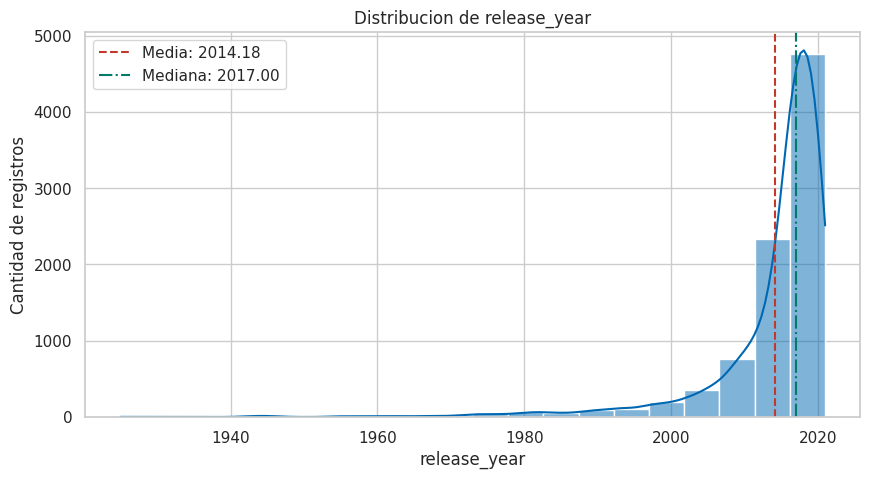

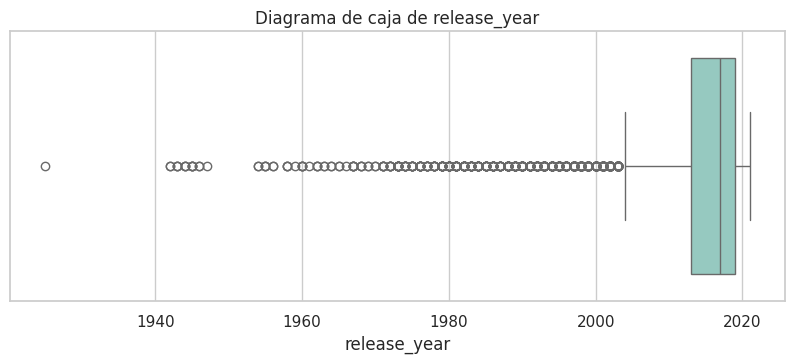

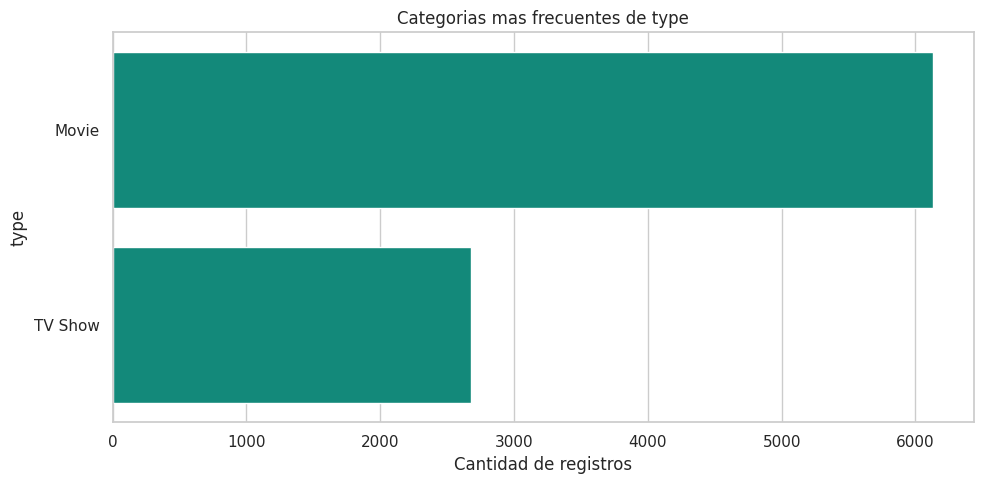

In [ ]:
columna_numerica = "release_year"
print("Columna numerica elegida:", columna_numerica)
media = df[columna_numerica].mean()
mediana = df[columna_numerica].median()

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x=columna_numerica, bins=20, kde=True, color="#0068B3")
plt.axvline(media, color="#C0392B", linestyle="--", label=f"Media: {media:.2f}")
plt.axvline(mediana, color="#007A6A", linestyle="-.", label=f"Mediana: {mediana:.2f}")
plt.title(f"Distribucion de {columna_numerica}")
plt.xlabel(columna_numerica)
plt.ylabel("Cantidad de registros")
plt.legend()
plt.show()
plt.figure(figsize=(10, 3.5))
sns.boxplot(x=df[columna_numerica], color="#8ED1C6")
plt.title(f"Diagrama de caja de {columna_numerica}")
plt.xlabel(columna_numerica)
plt.show()
top_categorias = df[columna_categorica].value_counts(dropna=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_categorias.values,
    y=top_categorias.index.astype(str),
    color="#009C88"
)
plt.title(f"Categorias mas frecuentes de {columna_categorica}")
plt.xlabel("Cantidad de registros")
plt.ylabel(columna_categorica)
plt.tight_layout()
plt.show()

# Aplicación de CRISP-DM

## 1. Business Understanding (Comprensión del Negocio)
El objetivo es optimizar la toma de decisiones en la adquisición y catalogación de contenidos dentro de la plataforma de streaming. Actualmente, el catálogo cuenta con una marcada asimetría hacia producciones recientes (mediana 2017) y una clara dominancia de largometrajes (69.62% películas frente a 30.38% series). La meta analítica del negocio consiste en predecir y clasificar de forma temprana el formato de contenido (`type`: Movie vs. TV Show) y su orientación de audiencia (`rating`, liderado por TV-MA con 3,207 títulos) a partir de los metadatos de producción (país de origen, duración proyectada y géneros en `listed_in`). Esta priorización evitará saturar la oferta en segmentos sobre-representados y permitirá balancear el catálogo hacia formatos con menor cobertura o con mayor potencial de retención.

## 2. Data Understanding (Comprensión de los Datos)
A partir del análisis exploratorio (EDA) sobre las 8,807 filas del conjunto de datos, se identificó que la variable temporal `release_year` abarca desde 1925 hasta 2021, aunque el 75% del catálogo se concentra entre 2013 y 2021 (rango intercuartílico de solo 6 años). Geográficamente existe una fuerte centralización en Estados Unidos (2,818 producciones dentro de los 748 países registrados). En términos de calidad, se detectó una ausencia relevante de información en `director` (2,634 valores nulos, ~29.9%) y en menor medida en `cast` (825 nulos) y `country` (831 nulos). Por el contrario, los campos operativos como `show_id` y `title` presentan unicidad absoluta (8,807 registros únicos), y columnas como `date_added` y `duration` presentan una tasa de completitud superior al 99.8%.

## 3. Data Preparation (Preparación de los Datos)
Para preparar el dataset para el modelamiento, se imputarán los valores nulos en variables categóricas críticas: las filas sin `director` y `cast` se clasificarán bajo la categoría sintética `'Unknown'` para no descartar el 30% del volumen de datos. En las columnas de texto combinado como `listed_in` y `country` se aplicará binarización multietiqueta (*Multi-Label Binarization*) o codificación *One-Hot*, agrupando países con frecuencias marginales en una categoría consolidada `'Other'`. Para la variable `duration`, se realizará una limpieza estructural separando los registros por unidad de medida: convirtiendo los minutos en valores numéricos continuos para películas y extrayendo el número de temporadas como variable discreta entera para series. Finalmente, se normalizarán numéricamente las escalas temporales y se dividirá el conjunto en particiones estratificadas de entrenamiento (80%) y prueba (20%).

## 4. Modeling (Modelado)
Dado que la variable objetivo principal es categórica binaria (`type`: Movie vs. TV Show), se implementará un enfoque de aprendizaje supervisado de clasificación. Como modelo base o de referencia (*baseline*) se ajustará un árbol de decisión (*Decision Tree Classifier*) por su alta interpretabilidad de reglas directas. Posteriormente, se entrenará un clasificador de Bosques Aleatorios (*Random Forest Classifier*) para capturar interacciones no lineales complejas entre los géneros, países y tiempos de duración sin sobreajustar. Adicionalmente, se calibrará una Regresión Logística como alternativa lineal de baja complejidad computacional, comparando su capacidad de convergencia y robustez frente a la dimensionalidad generada por las etiquetas de género y países codificados.

## 5. Evaluation (Evaluación)
El éxito del modelo se medirá mediante métricas de clasificación ponderadas que mitiguen el desbalance de clases (aproximadamente una proporción 70/30 en favor de películas). En lugar de considerar únicamente la exactitud (*Accuracy*), se evaluará la matriz de confusión, el valor de *F1-Score* ponderado y el área bajo la curva ROC (ROC-AUC) sobre el conjunto de prueba independiente (*test set*). El criterio de aceptación del negocio exige que el modelo alcance un F1-Score mínimo de 0.82 en la clase minoritaria (`TV Show`) para garantizar que el sistema no se limite a clasificar trivialmente todas las observaciones como películas, asegurando que la recomendación de formato sea confiable en entornos de evaluación fuera de muestra.

## 6. Deployment (Despliegue)
La solución se proyecta como un módulo analítico interno integrado al pipeline de ingesta de contenido del equipo editorial. Cuando un nuevo proyecto audiovisual entra en etapa de pre-adquisición con su ficha de metadatos preliminar (género, país, equipo directivo y duración tentativa), el modelo generará una puntuación de ajuste de formato y segmentación por edad recomendada antes de la firma de contratos. El sistema registrará las sugerencias emitidas, las decisiones finales del equipo y el rendimiento de los títulos en producción para alimentar un tablero de monitoreo mensual, asegurando una revisión humana obligatoria que prevenga sesgos territoriales o asignaciones erróneas.

---

### Respuestas a las Preguntas de Cierre

1. **¿Qué fase te resultó más difícil de conectar con tu dataset real? ¿Por qué?**  
   La fase de **Deployment (Despliegue)**, porque al trabajar con un dataset estático de Kaggle que refleja un catálogo histórico cerrado (hasta 2021), requiere un esfuerzo conceptual proyectar cómo estos datos pasarían a un entorno de producción operativo y en tiempo real, definiendo procesos de integración humana y flujos diarios que no existen dentro de una simple tabla CSV.

2. **¿Cambiarías el objetivo de negocio que planteaste al inicio del Laboratorio 01?**  
   Sí; al inicio del EDA el análisis se orientaba de manera general a entender la popularidad histórica del catálogo, pero los hallazgos demostraron que el verdadero problema es el desbalance estructural (casi 70% películas y una saturación de contenido adulto TV-MA). El objetivo de negocio debe reenfocarse en optimizar decisiones de compra y balance de catálogo antes de invertir en licencias.

3. **¿Qué información adicional necesitarías para completar mejor la fase de Evaluation?**  
   Se requerirían variables directas de rendimiento e impacto de negocio, tales como: horas totales de reproducción por título (*watch time*), tasa de retención o abandono de usuarios por contenido, y costos de licenciamiento/adquisición. Con estos datos, la evaluación no sería solo estadística (F1-score), sino que podría traducirse directamente en retorno de inversión (ROI) para la plataforma.

hallazgos:
1-  del catalogo, la mayoria corresponde a peliculas (69.62%) y en series (30.38%)
2-  estados unidos domina la producciones con un 35%.
3-  la categoria TV-MA es la mas comun estre las categorias de edad.
4-  1793 series cuentan solo con una temporada.
5-  95% del catalogo se estreno despues del 1997.


